### Q6.1

In [ ]:
# Import necessary libraries
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
import numpy as np

# 1. Load the MNIST digits dataset
# The dataset consists of 8x8 pixel images of handwritten digits 
digits = load_digits()
X = digits.data  # Feature data (pixel values)
y = digits.target # Target data (the digit labels 0-9)

print(f"Original dataset shape: {X.shape}")
print(f"Number of unique labels: {len(np.unique(y))}")

# 2. Split the dataset into training and testing sets
# We'll use an 80-20 split for training and testing data, respectively.
# Setting random_state=42 ensures that the split is the same every time,
# making our results reproducible.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, 
    test_size=0.2, 
    random_state=42,
    stratify=y # stratify ensures the proportion of labels is the same in train and test sets
)

# Print the shapes of the resulting datasets to verify the split
print("\n--- After Splitting ---")
print(f"X_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"X_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

Original dataset shape: (1797, 64)
Number of unique labels: 10

--- After Splitting ---
X_train shape: (1437, 64)
y_train shape: (1437,)
X_test shape: (360, 64)
y_test shape: (360,)


### Q6.2

In [2]:
import numpy as np

class PCA:
    """
    A custom implementation of Principal Component Analysis (PCA) from scratch.

    This class is used to reduce the dimensionality of data by projecting it onto
    a lower-dimensional space defined by its principal components.

    Parameters
    ----------
    n_components : int
        The number of principal components to keep.

    Attributes
    ----------
    mean_ : np.ndarray
        The mean of each feature in the training data.
    components_ : np.ndarray
        The principal components (eigenvectors of the covariance matrix).
    explained_variance_ratio_ : np.ndarray
        The percentage of variance explained by each of the selected components.
    """

    def __init__(self, n_components):
        """
        Initializes the PCA model.

        Parameters
        ----------
        n_components : int
            The number of principal components to keep.
        """
        if n_components <= 0:
            raise ValueError("n_components must be a positive integer.")
        self.n_components = n_components
        self.components_ = None
        self.mean_ = None
        self.explained_variance_ratio_ = None

    def fit(self, X):
        """
        Computes the principal components from the training data.

        The fitting process involves centering the data, computing the covariance
        matrix, and then finding its eigenvectors and eigenvalues to determine
        the principal components.

        Parameters
        ----------
        X : np.ndarray of shape (n_samples, n_features)
            The training data to fit the model on.
        """
        # Step 1: Calculate the mean of each feature and center the data.
        # Centering is crucial for PCA to work correctly.
        self.mean_ = np.mean(X, axis=0)
        X_centered = X - self.mean_

        # Step 2: Compute the covariance matrix.
        # `rowvar=False` indicates that columns are features and rows are samples.
        cov_matrix = np.cov(X_centered, rowvar=False)

        # Step 3: Calculate the eigenvalues and eigenvectors of the covariance matrix.
        # Eigenvectors represent the directions of maximum variance (principal components).
        # Eigenvalues represent the magnitude of variance in those directions.
        eigenvalues, eigenvectors = np.linalg.eigh(cov_matrix)
        
        # Step 4: Sort eigenvalues and corresponding eigenvectors in descending order.
        # This ranks the principal components by their importance.
        sorted_indices = np.argsort(eigenvalues)[::-1]
        sorted_eigenvalues = eigenvalues[sorted_indices]
        sorted_eigenvectors = eigenvectors[:, sorted_indices]
        
        # Step 5: Store the top `n_components` eigenvectors.
        # These form the new feature space.
        self.components_ = sorted_eigenvectors[:, :self.n_components]
        
        # Step 6: Calculate the explained variance ratio for each component.
        # This shows how much information is captured by each principal component.
        total_variance = np.sum(sorted_eigenvalues)
        self.explained_variance_ratio_ = sorted_eigenvalues / total_variance

    def transform(self, X):
        """
        Projects the data onto the principal components to reduce dimensionality.

        Parameters
        ----------
        X : np.ndarray of shape (n_samples, n_features)
            The data to transform.
        
        Returns
        -------
        np.ndarray of shape (n_samples, n_components)
            The transformed data in the lower-dimensional space.
        """
        if self.components_ is None:
            raise RuntimeError("PCA has not been fitted yet. Call fit() first.")
        
        # Center the data using the mean *from the training set*.
        X_centered = X - self.mean_

        # Project the centered data onto the principal components via dot product.
        transformed_data = np.dot(X_centered, self.components_)
        return transformed_data

    def inverse_transform(self, X_transformed):
        """
        Transforms data from the reduced space back to its original space.

        Parameters
        ----------
        X_transformed : np.ndarray of shape (n_samples, n_components)
            The data in the lower-dimensional space.

        Returns
        -------
        np.ndarray of shape (n_samples, n_features)
            The reconstructed data in the original feature space.
        """
        if self.components_ is None:
            raise RuntimeError("PCA has not been fitted yet. Call fit() first.")
        
        # Reverse the projection using the transpose of the components matrix.
        X_reconstructed_centered = np.dot(X_transformed, self.components_.T)
        
        # Add the original mean back to de-center the data.
        X_reconstructed = X_reconstructed_centered + self.mean_
        return X_reconstructed

    def checkPCA(self, X):
        """
        Checks if the class reduces the dimensions appropriately.

        Parameters
        ----------
        X : np.ndarray
            The data to test the transformation on.
        
        Returns
        -------
        bool
            True if the transformation reduces to the correct number of dimensions,
            False otherwise.
        """
        try:
            # Attempt to transform the data.
            transformed_data = self.transform(X)
            
            # Verify that the output has the expected number of features (columns).
            if transformed_data.shape[1] == self.n_components:
                print(f"Check successful: Original shape {X.shape} -> Transformed shape {transformed_data.shape}")
                return True
            else:
                print(f"Check failed: Transformed data has {transformed_data.shape[1]} columns, expected {self.n_components}.")
                return False
        except Exception as e:
            print(f"An error occurred during checkPCA: {e}")
            return False

In [3]:
# Define the list of dimensions to reduce the data to.
n_components_list = [2, 5, 10, 20, 30, 40, 50, 64]

# Dictionaries to store the transformed data
X_train_pca = {}
X_test_pca = {}

print("--- Applying PCA for different n_components ---")

# For each value in n_components_list, fit PCA and transform the data.
for n in n_components_list:
    # 1. Initialize your custom PCA model with n components.
    pca_model = PCA(n_components=n)
    
    # 2. Fit the model *only* on the training data.
    pca_model.fit(X_train)
    
    # 3. Transform both the training and testing data using the fitted model.
    X_train_transformed = pca_model.transform(X_train)
    X_test_transformed = pca_model.transform(X_test)
    
    # 4. Store the transformed data in our dictionaries.
    X_train_pca[n] = X_train_transformed
    X_test_pca[n] = X_test_transformed
    
    print(f"n = {n:2}: Transformed X_train shape: {X_train_transformed.shape}, "
          f"Transformed X_test shape: {X_test_transformed.shape}")

--- Applying PCA for different n_components ---
n =  2: Transformed X_train shape: (1437, 2), Transformed X_test shape: (360, 2)
n =  5: Transformed X_train shape: (1437, 5), Transformed X_test shape: (360, 5)
n = 10: Transformed X_train shape: (1437, 10), Transformed X_test shape: (360, 10)
n = 20: Transformed X_train shape: (1437, 20), Transformed X_test shape: (360, 20)
n = 30: Transformed X_train shape: (1437, 30), Transformed X_test shape: (360, 30)
n = 40: Transformed X_train shape: (1437, 40), Transformed X_test shape: (360, 40)
n = 50: Transformed X_train shape: (1437, 50), Transformed X_test shape: (360, 50)
n = 64: Transformed X_train shape: (1437, 64), Transformed X_test shape: (360, 64)


### Q6.3

In [4]:
# Import the classifier and accuracy metric
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score

# Define the list of k values to test.
k_values = [5, 25, 50, 100]

# Dictionary to store the accuracy results
# Format: results[n_components][k] = accuracy
results = {}

print("--- Training and Evaluating KNN Classifiers ---")

# For each number of principal components...
for n in n_components_list:
    results[n] = {} # Initialize a sub-dictionary for the current n
    
    # Retrieve the corresponding transformed data
    current_X_train = X_train_pca[n]
    current_X_test = X_test_pca[n]
    
    print(f"\nEvaluating for n_components = {n}")
    
    # ...and for each k value...
    for k in k_values:
        # 1. Initialize the KNN model with the current k.
        knn = KNeighborsClassifier(n_neighbors=k)
        
        # 2. Train the model on the transformed training data.
        knn.fit(current_X_train, y_train)
        
        # 3. Predict on the transformed test data.
        y_pred = knn.predict(current_X_test)
        
        # 4. Calculate and store the accuracy.
        accuracy = accuracy_score(y_test, y_pred)
        results[n][k] = accuracy
        
        print(f"  k = {k:3}: Accuracy = {accuracy:.4f}")

--- Training and Evaluating KNN Classifiers ---

Evaluating for n_components = 2
  k =   5: Accuracy = 0.6111
  k =  25: Accuracy = 0.6333
  k =  50: Accuracy = 0.6361
  k = 100: Accuracy = 0.6250

Evaluating for n_components = 5
  k =   5: Accuracy = 0.9278
  k =  25: Accuracy = 0.9194
  k =  50: Accuracy = 0.8861
  k = 100: Accuracy = 0.8361

Evaluating for n_components = 10
  k =   5: Accuracy = 0.9583
  k =  25: Accuracy = 0.9417
  k =  50: Accuracy = 0.9167
  k = 100: Accuracy = 0.8972

Evaluating for n_components = 20
  k =   5: Accuracy = 0.9861
  k =  25: Accuracy = 0.9611
  k =  50: Accuracy = 0.9333
  k = 100: Accuracy = 0.9111

Evaluating for n_components = 30
  k =   5: Accuracy = 0.9806
  k =  25: Accuracy = 0.9611
  k =  50: Accuracy = 0.9306
  k = 100: Accuracy = 0.9056

Evaluating for n_components = 40
  k =   5: Accuracy = 0.9833
  k =  25: Accuracy = 0.9583
  k =  50: Accuracy = 0.9333
  k = 100: Accuracy = 0.9111

Evaluating for n_components = 50
  k =   5: Accuracy 

### Q6.4

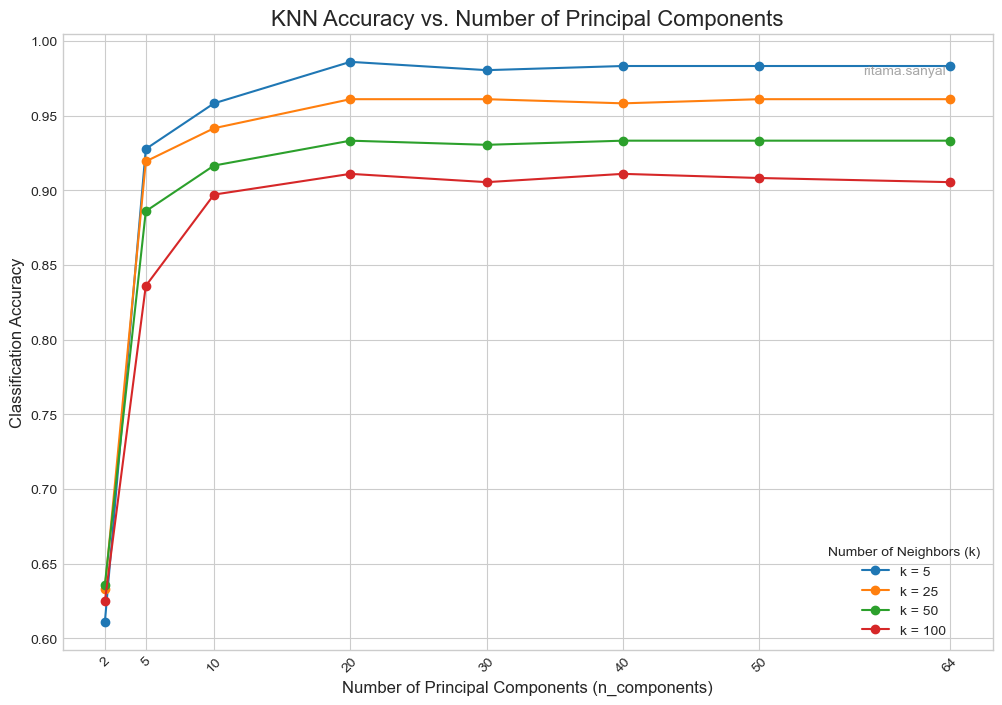

In [8]:
import matplotlib.pyplot as plt

# --- Plotting ---
plt.style.use('seaborn-v0_8-whitegrid')
fig, ax = plt.subplots(figsize=(12, 8))

# Plot a line for each k value
for k in k_values:
    # Get the accuracies for the current k across all n_components
    accuracies = [results[n][k] for n in n_components_list]
    ax.plot(n_components_list, accuracies, marker='o', linestyle='-', label=f'k = {k}')

# --- Formatting the Plot ---
# Add title and labels as required by the assignment instructions
ax.set_title('KNN Accuracy vs. Number of Principal Components', fontsize=16)
ax.set_xlabel('Number of Principal Components (n_components)', fontsize=12)
ax.set_ylabel('Classification Accuracy', fontsize=12)
ax.legend(title='Number of Neighbors (k)', fontsize=10)
ax.set_xticks(n_components_list) # Ensure all n_component values are shown on the x-axis
plt.xticks(rotation=45)

# Per assignment instructions, add username to plot
# Replace 'username' with your actual username
plt.text(
0.95, 0.95, "ritama.sanyal",
ha='right', va='top',
transform=plt.gca().transAxes ,
fontsize=10, color='gray', alpha=0.7
)

plt.show()

## Effect of Principal Components on Accuracy

Increasing the number of principal components **dramatically improves** the KNN classifier's accuracy, but only up to a certain point.  
As seen in the graph, accuracy for all `k` values rises steeply when moving from **2 to 20 components**.  
For example, the accuracy for `k=5` (the blue line) jumps from approximately **0.61 to nearly 0.99** in this range.  
After this point, the performance gains level off.

---

## Influence of K

The choice of `k` (the number of neighbors) sets the **overall performance ceiling**:

- A **smaller `k` (k=5)** consistently achieves the **highest accuracy** across all component counts.  
- As `k` increases to **25, 50, and 100**, the maximum accuracy achieved by the classifier progressively decreases.

While `k` affects the **absolute accuracy**, it does not change the general trend:  
for every `k` value, the relationship shows a **sharp initial improvement followed by a plateau**.

---

## Point of Diminishing Returns

There is a clear **point of diminishing returns** at approximately **20 principal components**.  
After this point, the accuracy curves for all `k` values **flatten out significantly**.  

Adding more components beyond this point (from **20 to 64**) yields almost no improvement in accuracy.  
This "elbow" in the graph suggests that the **first 20 components capture most of the essential information** for classification,  
and further components add little predictive value.


https://g.co/gemini/share/136cd55e3c23